# Türkçe Metinlerde Duygu Analizi: TREMO Üzerinde Bağımsız Yeniden Üretim ve Sağlamlık Analizi

**Referans makale:** Toçoğlu vd. (2019), *Türkçe Metinlerde Duygu Analizi İçin Farklı Makine Öğrenmesi Yöntemlerinin Karşılaştırılması*, DEÜ FMD 21(63).

**Bu defterde yapılanlar**
1. Veri setinin yüklenmesi ve makaledeki Tablo 2 ile doğrulanması
2. Model karşılaştırması (5 katlı gruplu çapraz doğrulama) ve McNemar testi
3. Kök bulma karşılaştırması (stemsiz / F5 / TurkishStemmer)
4. Ablasyon: bigram etkisi, MI özellik seçimi ve veri sızıntısı etkisi
5. Rastgele bölme ile gruplu bölme karşılaştırması
6. En iyi modelin hata analizi

**Not:** `HEAVY = True` iken tüm hücrelerin toplam süresi yaklaşık 1-1,5 saattir. Hızlı deneme için 1. hücrede `HEAVY = False` yapın.

## 1. Kurulum ve ayarlar

In [1]:
# ============================================================
# 1) KURULUM, KÜTÜPHANELER VE GENEL AYARLAR
# ============================================================
!pip install -q kagglehub TurkishStemmer xgboost statsmodels

import os, re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from statsmodels.stats.contingency_tables import mcnemar
from TurkishStemmer import TurkishStemmer

warnings.filterwarnings("ignore")

SEED = 42          # tekrarlanabilirlik için sabit tohum
HEAVY = True       # False: yavaş modeller (RF, ExtraTrees, MLP, XGBoost) atlanır
OUT_DIR = "ciktilar"
os.makedirs(OUT_DIR, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})
MAVI, YESIL, TURUNCU, GRI = "#2b6cb0", "#2f855a", "#dd6b20", "#a0aec0"

def baslik(metin):
    display(Markdown(f"### {metin}"))

def kaydet_fig(fig, ad):
    fig.savefig(f"{OUT_DIR}/{ad}.png", dpi=200, bbox_inches="tight")

def kaydet_tablo(df, ad):
    df.to_csv(f"{OUT_DIR}/{ad}.csv", index=False, encoding="utf-8-sig")

print("Kurulum tamam.")

Kurulum tamam.


## 2. Veri seti: yükleme, filtreleme ve makale ile doğrulama

In [2]:
# ============================================================
# 2) VERİYİ YÜKLE (Kaggle'dan, Colab'a), FİLTRELE, TEMİZLE
# ============================================================
import kagglehub
yol = kagglehub.dataset_download("mansuralp/tremo")
xml_yolu = os.path.join(yol, "TREMODATA.xml")

kok = ET.parse(xml_yolu).getroot()
ham = pd.DataFrame([{
    "text":      d.findtext("Entry") or "",
    "validated": d.findtext("ValidatedEmotion"),   # oylama sonrası etiket (makale bunu kullanıyor)
    "condition": d.findtext("Condition"),          # Consensus / Majority of Votes / Reject
} for d in kok.findall("Doc")])

def tr_kucuk(s):
    # Türkçe I/İ sorunu: "IŞIK".lower() bozuk çıkar, önce elle düzeltiyoruz
    return s.replace("I", "\u0131").replace("\u0130", "i").lower()

# Reject = oylamada belirsiz kalan 1.361 belge, makale de bunları çıkarmış
data = ham[ham["condition"] != "Reject"].reset_index(drop=True)
data["clean"] = data["text"].str.strip().map(tr_kucuk)

# --- Makaledeki Tablo 2 ile karşılaştırma ---
makale_t2 = {"Happy": 5229, "Fear": 4393, "Anger": 4723,
             "Sadness": 5021, "Disgust": 3620, "Surprise": 3003}
tr_ad = {"Happy": "Mutluluk", "Fear": "Korku", "Anger": "Öfke",
         "Sadness": "Üzüntü", "Disgust": "Tiksinme", "Surprise": "Şaşırma"}
sayim = data["validated"].value_counts()
t2 = pd.DataFrame({
    "Duygu": list(makale_t2),
    "Türkçe": [tr_ad[k] for k in makale_t2],
    "Bizim veri": [int(sayim.get(k, 0)) for k in makale_t2],
    "Makale Tablo 2": list(makale_t2.values()),
})
t2["Eşleşme"] = np.where(t2["Bizim veri"] == t2["Makale Tablo 2"], "✓", "✗")
baslik("Sınıf dağılımı: bizim veri vs. makale Tablo 2")
display(t2.style.hide(axis="index")
        .map(lambda v: "background-color:#c6f6d5;font-weight:bold" if v == "✓"
             else ("background-color:#fed7d7" if v == "✗" else ""), subset=["Eşleşme"])
        .set_properties(subset=["Bizim veri", "Makale Tablo 2"], **{"text-align": "right"}))
kaydet_tablo(t2, "tablo_veri_dogrulama")

# --- Veri kalitesi özeti ---
celiski = int((data.groupby("clean")["validated"].nunique() > 1).sum())
ozet = pd.DataFrame({
    "Ölçüt": ["Ham belge sayısı", "Reject (çıkarılan) belge", "Kullanılan belge",
              "Benzersiz metin", "Tekrarlı metin içeren satır",
              "Birden fazla etiket alan metin", "Ortalama kelime sayısı"],
    "Değer": [len(ham), int((ham["condition"] == "Reject").sum()), len(data),
              data["clean"].nunique(), int(data["clean"].duplicated(keep=False).sum()),
              celiski, round(data["clean"].str.split().str.len().mean(), 2)],
})
baslik("Veri kalitesi özeti")
display(ozet.style.hide(axis="index").background_gradient(cmap="Blues", subset=["Değer"]))
kaydet_tablo(ozet, "tablo_veri_ozeti")

100%|██████████| 1.46M/1.46M [00:00<00:00, 34.4MB/s]

Extracting files...


### Sınıf dağılımı: bizim veri vs. makale Tablo 2

Duygu,Türkçe,Bizim veri,Makale Tablo 2,Eşleşme
Happy,Mutluluk,5229,5229,✓
Fear,Korku,4393,4393,✓
Anger,Öfke,4723,4723,✓
Sadness,Üzüntü,5021,5021,✓
Disgust,Tiksinme,3620,3620,✓
Surprise,Şaşırma,3003,3003,✓


### Veri kalitesi özeti

Ölçüt,Değer
Ham belge sayısı,27350.000000
Reject (çıkarılan) belge,1361.000000
Kullanılan belge,25989.000000
Benzersiz metin,23687.000000
Tekrarlı metin içeren satır,3224.000000
Birden fazla etiket alan metin,65.000000
Ortalama kelime sayısı,5.930000


## 3. Çapraz doğrulama katları ve ön işleme

- **Gruplu 5 katlı CV:** Aynı metin her zaman tek tarafta (eğitim ya da test) kalır; tekrarlı cümleler kaynaklı sızıntı önlenir.
- Tüm deneylerde **aynı katlar** kullanılır, böylece karşılaştırmalar adil ve eşleştirilmiş olur.
- Vektörleştirme (TF-IDF) ve özellik seçimi her katın **içinde**, yalnızca eğitim verisiyle öğrenilir.

In [3]:
# ============================================================
# 3) KATLAR, KÖK BULMA VE YARDIMCI FONKSİYONLAR
# ============================================================
X = data["clean"].values
le = LabelEncoder()
y = le.fit_transform(data["validated"])
SINIFLAR = list(le.classes_)

# Aynı metin = aynı grup -> aynı tarafta kalır
folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y, X))
print("Kat boyutları (eğitim/test):", [(len(a), len(b)) for a, b in folds])
print("Katlar arası ortak metin (0 olmalı):", [len(set(X[a]) & set(X[b])) for a, b in folds])

# --- Kök bulma varyantları ---
TOKEN = re.compile(r"\w+")
_ts, _onbellek = TurkishStemmer(), {}
def ts_kok(w):
    if w not in _onbellek:
        try:    _onbellek[w] = _ts.stem(w)
        except Exception: _onbellek[w] = w
    return _onbellek[w]

def donustur(metinler, fn):
    return np.array([" ".join(fn(w) for w in TOKEN.findall(t)) for t in metinler])

X_stemsiz = donustur(X, lambda w: w)         # kök bulma yok
X_f5      = donustur(X, lambda w: w[:5])     # makaledeki F5 (ilk 5 harf)
X_ts      = donustur(X, ts_kok)              # TurkishStemmer

# --- Değerlendirme fonksiyonu (kat içinde TF-IDF [+ MI seçimi] + sınıflandırıcı) ---
def mi_skor(X_, y_):
    # kelime var/yok bilgisi üzerinden karşılıklı bilgi (MI)
    return mutual_info_classif((X_ > 0).astype(np.float64), y_, discrete_features=True)

def cv_calistir(X_, ngram, clf, mi_k=None, katlar=None):
    katlar = folds if katlar is None else katlar
    adimlar = [("tfidf", TfidfVectorizer(min_df=2, ngram_range=ngram))]
    if mi_k: adimlar.append(("sec", SelectKBest(mi_skor, k=mi_k)))
    adimlar.append(("clf", clone(clf)))
    tahmin, acc, f1 = np.zeros(len(y), dtype=int), [], []
    for tr, te in katlar:
        p = Pipeline(adimlar).fit(X_[tr], y[tr]).predict(X_[te])
        tahmin[te] = p
        acc.append(accuracy_score(y[te], p))
        f1.append(f1_score(y[te], p, average="macro"))
    return {"acc": np.array(acc), "f1": np.array(f1), "tahmin": tahmin}

def pm(a):  # "ortalama ± std" metni (yüzde)
    return f"{100*a.mean():.2f} ± {100*a.std():.2f}"

def fark(a, b):  # kat bazında eşleştirilmiş doğruluk farkı (puan)
    d = 100 * (a["acc"] - b["acc"])
    return d.mean(), d.std(), int((d > 0).sum())

Kat boyutları (eğitim/test): [(20742, 5247), (20854, 5135), (20717, 5272), (20835, 5154), (20808, 5181)]
Katlar arası ortak metin (0 olmalı): [0, 0, 0, 0, 0]


## 4. Deney 1: Model karşılaştırması

Tüm modeller F5 kök bulma + TF-IDF üzerinde, aynı katlarla. Hiperparametreler büyük ölçüde varsayılan (ağaç modelleri **ayarsız**). Linear SVM için C=0,3 küçük bir arama ile seçildi.

Logistic Regression        acc=87.17 ± 0.61  F1=87.35 ± 0.62  (17 sn)
Linear SVM                 acc=87.63 ± 0.61  F1=87.80 ± 0.62  (7 sn)
Linear SVM (uni+bigram)    acc=88.40 ± 0.43  F1=88.52 ± 0.44  (8 sn)
Random Forest              acc=84.79 ± 0.72  F1=85.06 ± 0.70  (275 sn)
Extra Trees                acc=85.40 ± 0.70  F1=85.61 ± 0.63  (412 sn)
MLP (256)                  acc=87.07 ± 0.40  F1=87.21 ± 0.42  (202 sn)
XGBoost                    acc=84.49 ± 0.62  F1=84.95 ± 0.65  (544 sn)


### Model karşılaştırma tablosu (5 katlı gruplu CV, ortalama ± std)

Model,N-gram,Doğruluk (%),± acc,Macro-F1 (%),± F1,Süre (sn)
Linear SVM (uni+bigram),1-2,88.40,0.43,88.52,0.44,8
Linear SVM,1-1,87.63,0.61,87.80,0.62,7
Logistic Regression,1-1,87.17,0.61,87.35,0.62,17
MLP (256),1-1,87.07,0.40,87.21,0.42,202
Extra Trees,1-1,85.40,0.70,85.61,0.63,412
Random Forest,1-1,84.79,0.72,85.06,0.70,275
XGBoost,1-1,84.49,0.62,84.95,0.65,544


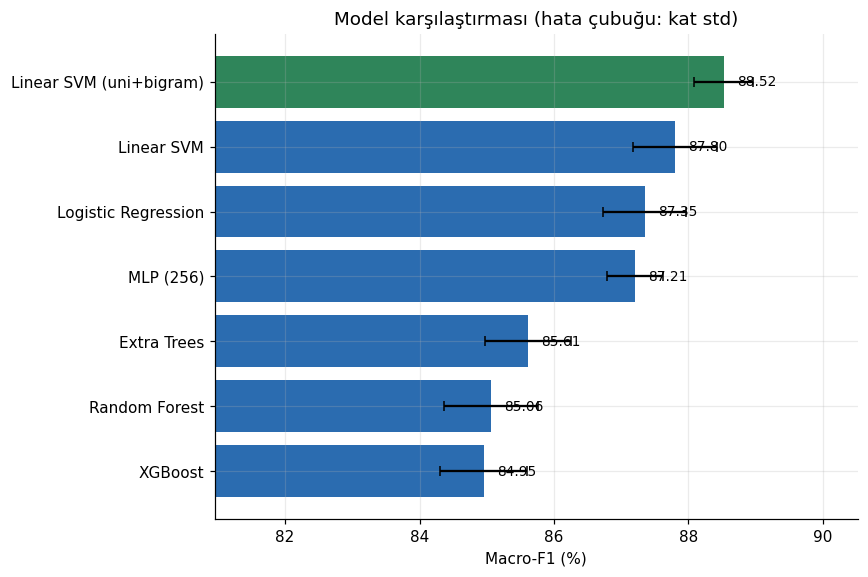

### McNemar testi p-değerleri (sarı: fark istatistiksel olarak anlamlı değil, p ≥ 0,05)

,Logistic Regression,Linear SVM,Linear SVM (uni+bigram),Random Forest,Extra Trees,MLP (256),XGBoost
Logistic Regression,-,0.0000,0.0000,0.0000,0.0000,0.4598,0.0000
Linear SVM,0.0000,-,0.0000,0.0000,0.0000,0.0000,0.0000
Linear SVM (uni+bigram),0.0000,0.0000,-,0.0000,0.0000,0.0000,0.0000
Random Forest,0.0000,0.0000,0.0000,-,0.0000,0.0000,0.0888
Extra Trees,0.0000,0.0000,0.0000,0.0000,-,0.0000,0.0000
MLP (256),0.4598,0.0000,0.0000,0.0000,0.0000,-,0.0000
XGBoost,0.0000,0.0000,0.0000,0.0888,0.0000,0.0000,-


Not: 26 bin belgede küçük farklar bile anlamlı çıkabilir; p-değeri ile birlikte farkın büyüklüğüne (tabloya) bakın.


In [4]:
# ============================================================
# 4) DENEY 1: MODEL KARŞILAŞTIRMASI + McNEMAR TESTİ
# ============================================================
modeller = {
    "Logistic Regression":      ((1, 1), LogisticRegression(max_iter=1000)),
    "Linear SVM":               ((1, 1), LinearSVC(C=0.3)),
    "Linear SVM (uni+bigram)":  ((1, 2), LinearSVC(C=0.3)),
}
if HEAVY:
    modeller.update({
        "Random Forest": ((1, 1), RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED)),
        "Extra Trees":   ((1, 1), ExtraTreesClassifier(n_estimators=300, n_jobs=-1, random_state=SEED)),
        "MLP (256)":     ((1, 1), MLPClassifier(hidden_layer_sizes=(256,), early_stopping=True,
                                               max_iter=50, random_state=SEED)),
        "XGBoost":       ((1, 1), XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6,
                                               tree_method="hist", n_jobs=-1, random_state=SEED)),
    })

sonuc1, sureler = {}, {}
for ad, (ng, clf) in modeller.items():
    t0 = time.time()
    sonuc1[ad] = cv_calistir(X_f5, ng, clf)
    sureler[ad] = time.time() - t0
    print(f"{ad:26s} acc={pm(sonuc1[ad]['acc'])}  F1={pm(sonuc1[ad]['f1'])}  ({sureler[ad]:.0f} sn)")

tab1 = pd.DataFrame([{
    "Model": ad, "N-gram": f"{ng[0]}-{ng[1]}",
    "Doğruluk (%)": 100 * sonuc1[ad]["acc"].mean(), "± acc": 100 * sonuc1[ad]["acc"].std(),
    "Macro-F1 (%)": 100 * sonuc1[ad]["f1"].mean(), "± F1": 100 * sonuc1[ad]["f1"].std(),
    "Süre (sn)": sureler[ad],
} for ad, (ng, _) in modeller.items()]).sort_values("Macro-F1 (%)", ascending=False).reset_index(drop=True)

baslik("Model karşılaştırma tablosu (5 katlı gruplu CV, ortalama ± std)")
display(tab1.style.hide(axis="index")
        .format({"Doğruluk (%)": "{:.2f}", "± acc": "{:.2f}", "Macro-F1 (%)": "{:.2f}",
                 "± F1": "{:.2f}", "Süre (sn)": "{:.0f}"})
        .background_gradient(cmap="Greens", subset=["Doğruluk (%)", "Macro-F1 (%)"])
        .background_gradient(cmap="Oranges", subset=["Süre (sn)"]))
kaydet_tablo(tab1, "tablo_model_karsilastirma")

# --- Grafik ---
fig, ax = plt.subplots(figsize=(8, 0.55 * len(tab1) + 1.5))
renk = [YESIL if i == 0 else MAVI for i in range(len(tab1))]
ax.barh(tab1["Model"][::-1], tab1["Macro-F1 (%)"][::-1], xerr=tab1["± F1"][::-1],
        color=renk[::-1], capsize=3)
ax.set_xlim(tab1["Macro-F1 (%)"].min() - 4, tab1["Macro-F1 (%)"].max() + 2)
ax.set_xlabel("Macro-F1 (%)"); ax.set_title("Model karşılaştırması (hata çubuğu: kat std)")
for i, v in enumerate(tab1["Macro-F1 (%)"][::-1]):
    ax.text(v + 0.2, i, f"{v:.2f}", va="center", fontsize=9)
plt.tight_layout(); kaydet_fig(fig, "grafik_model_karsilastirma"); plt.show()

# --- McNemar testi: iki modelin aynı belgelerdeki doğru/yanlış tahminleri ---
def mcnemar_p(a, b):
    ca, cb = sonuc1[a]["tahmin"] == y, sonuc1[b]["tahmin"] == y
    r = mcnemar([[0, int((ca & ~cb).sum())], [int((~ca & cb).sum()), 0]], exact=False, correction=True)
    return r.pvalue

isimler = list(modeller)
P = pd.DataFrame(np.nan, index=isimler, columns=isimler)
for i in isimler:
    for j in isimler:
        if i != j: P.loc[i, j] = mcnemar_p(i, j)

baslik("McNemar testi p-değerleri (sarı: fark istatistiksel olarak anlamlı değil, p ≥ 0,05)")
def mcnemar_renk(df):
    s = pd.DataFrame("", index=df.index, columns=df.columns)
    s[df >= 0.05] = "background-color:#fefcbf;font-weight:bold"
    s[df < 0.05] = "background-color:#e6fffa"
    return s
display(P.style.format("{:.4f}", na_rep="-").apply(mcnemar_renk, axis=None))
P.reset_index().rename(columns={"index": "Model"}).to_csv(f"{OUT_DIR}/tablo_mcnemar.csv", index=False)
print("Not: 26 bin belgede küçük farklar bile anlamlı çıkabilir; p-değeri ile birlikte farkın büyüklüğüne (tabloya) bakın.")

## 5. Deney 2: Kök bulma karşılaştırması

Aynı model (Linear SVM, C=0,3, unigram+bigram), aynı katlar. Yalnızca kök bulma yöntemi değişiyor.

### Kök bulma karşılaştırması

Yöntem,Doğruluk (%),± acc,Macro-F1 (%),± F1,Stemsize göre fark (puan)
Stemsiz,86.89,0.40,87.00,0.40,+0.00
F5 (makaledeki),88.40,0.43,88.52,0.44,+1.51
TurkishStemmer,88.23,0.38,88.32,0.41,+1.34


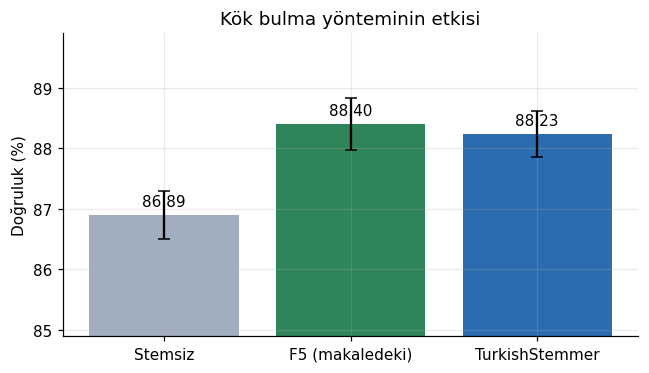

In [5]:
# ============================================================
# 5) DENEY 2: KÖK BULMA (STEMMING) KARŞILAŞTIRMASI
# ============================================================
svm = LinearSVC(C=0.3)
sonuc2 = {
    "Stemsiz":              cv_calistir(X_stemsiz, (1, 2), svm),
    "F5 (makaledeki)":      cv_calistir(X_f5,      (1, 2), svm),
    "TurkishStemmer":       cv_calistir(X_ts,      (1, 2), svm),
}
tab2 = pd.DataFrame([{
    "Yöntem": ad, "Doğruluk (%)": 100 * r["acc"].mean(), "± acc": 100 * r["acc"].std(),
    "Macro-F1 (%)": 100 * r["f1"].mean(), "± F1": 100 * r["f1"].std(),
    "Stemsize göre fark (puan)": 100 * (r["acc"] - sonuc2["Stemsiz"]["acc"]).mean(),
} for ad, r in sonuc2.items()])

baslik("Kök bulma karşılaştırması")
display(tab2.style.hide(axis="index")
        .format({"Doğruluk (%)": "{:.2f}", "± acc": "{:.2f}", "Macro-F1 (%)": "{:.2f}",
                 "± F1": "{:.2f}", "Stemsize göre fark (puan)": "{:+.2f}"})
        .background_gradient(cmap="Greens", subset=["Doğruluk (%)", "Macro-F1 (%)"]))
kaydet_tablo(tab2, "tablo_kok_bulma")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(tab2["Yöntem"], tab2["Doğruluk (%)"], yerr=tab2["± acc"], color=[GRI, YESIL, MAVI], capsize=4)
ax.set_ylim(tab2["Doğruluk (%)"].min() - 2, tab2["Doğruluk (%)"].max() + 1.5)
ax.set_ylabel("Doğruluk (%)"); ax.set_title("Kök bulma yönteminin etkisi")
for i, v in enumerate(tab2["Doğruluk (%)"]): ax.text(i, v + 0.15, f"{v:.2f}", ha="center")
plt.tight_layout(); kaydet_fig(fig, "grafik_kok_bulma"); plt.show()

## 6. Deney 3: Ablasyon (bigram, MI özellik seçimi ve veri sızıntısı)

Hepsi F5 + Linear SVM (C=0,3), aynı katlar. **Sızıntılı** kurulumda TF-IDF ve MI seçimi önce **tüm veride** yapılır, ardından çapraz doğrulama uygulanır (makalede seçimin bölmeden önce yapılmış olma riskini temsil eder).

### Ablasyon sonuçları

Kurulum,Doğruluk (%),± acc,Macro-F1 (%)
"1) Unigram, seçimsiz",87.63,0.61,87.80
"2) Unigram+bigram, seçimsiz",88.40,0.43,88.52
"3) Unigram, MI K=1500 (katın içinde, doğru)",87.21,0.49,87.42
"4) Unigram, MI K=1500 (bölmeden önce, sızıntılı)",87.68,0.54,87.89


### Kat bazında eşleştirilmiş doğruluk farkları

Karşılaştırma,Ortalama fark (puan),Std (puan),Pozitif kat sayısı (5 üzerinden)
Bigram etkisi (2 - 1),+0.77,0.28,5
MI seçiminin maliyeti (3 - 1),-0.41,0.19,0
Sızıntı etkisi (4 - 3),+0.47,0.09,5


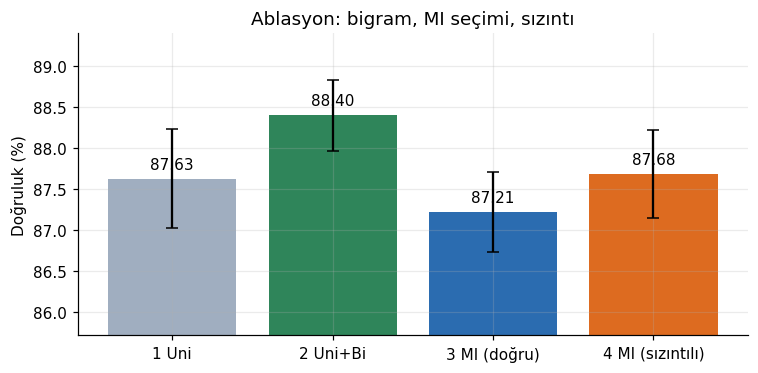

In [6]:
# ============================================================
# 6) DENEY 3: ABLASYON
# ============================================================
K_MI = 1500   # makaledeki 1.397 özelliğe yakın
svm = LinearSVC(C=0.3)

a1 = cv_calistir(X_f5, (1, 1), svm)                  # 1) unigram, seçimsiz
a2 = cv_calistir(X_f5, (1, 2), svm)                  # 2) unigram+bigram, seçimsiz
a3 = cv_calistir(X_f5, (1, 1), svm, mi_k=K_MI)       # 3) MI seçimi katın İÇİNDE (doğru)

# 4) MI seçimi bölmeden ÖNCE tüm veride (sızıntılı)
Xt = TfidfVectorizer(min_df=2).fit_transform(X_f5)
Xs = SelectKBest(mi_skor, k=K_MI).fit(Xt, y).transform(Xt)
acc4, f14 = [], []
for tr, te in folds:
    p = clone(svm).fit(Xs[tr], y[tr]).predict(Xs[te])
    acc4.append(accuracy_score(y[te], p)); f14.append(f1_score(y[te], p, average="macro"))
a4 = {"acc": np.array(acc4), "f1": np.array(f14)}

tab3 = pd.DataFrame({
    "Kurulum": ["1) Unigram, seçimsiz", "2) Unigram+bigram, seçimsiz",
                f"3) Unigram, MI K={K_MI} (katın içinde, doğru)",
                f"4) Unigram, MI K={K_MI} (bölmeden önce, sızıntılı)"],
    "Doğruluk (%)": [100 * r["acc"].mean() for r in (a1, a2, a3, a4)],
    "± acc": [100 * r["acc"].std() for r in (a1, a2, a3, a4)],
    "Macro-F1 (%)": [100 * r["f1"].mean() for r in (a1, a2, a3, a4)],
})
baslik("Ablasyon sonuçları")
display(tab3.style.hide(axis="index")
        .format({"Doğruluk (%)": "{:.2f}", "± acc": "{:.2f}", "Macro-F1 (%)": "{:.2f}"})
        .background_gradient(cmap="Greens", subset=["Doğruluk (%)", "Macro-F1 (%)"]))
kaydet_tablo(tab3, "tablo_ablasyon")

# --- Kat bazında eşleştirilmiş farklar ---
karsilastirma = [("Bigram etkisi (2 - 1)", a2, a1),
                 ("MI seçiminin maliyeti (3 - 1)", a3, a1),
                 ("Sızıntı etkisi (4 - 3)", a4, a3)]
tab3b = pd.DataFrame([{
    "Karşılaştırma": ad, "Ortalama fark (puan)": fark(a, b)[0],
    "Std (puan)": fark(a, b)[1], "Pozitif kat sayısı (5 üzerinden)": fark(a, b)[2],
} for ad, a, b in karsilastirma])
baslik("Kat bazında eşleştirilmiş doğruluk farkları")
display(tab3b.style.hide(axis="index")
        .format({"Ortalama fark (puan)": "{:+.2f}", "Std (puan)": "{:.2f}"})
        .map(lambda v: "color:#276749;font-weight:bold" if v > 0 else "color:#c53030;font-weight:bold",
             subset=["Ortalama fark (puan)"]))
kaydet_tablo(tab3b, "tablo_ablasyon_farklar")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(["1 Uni", "2 Uni+Bi", "3 MI (doğru)", "4 MI (sızıntılı)"], tab3["Doğruluk (%)"],
       yerr=tab3["± acc"], color=[GRI, YESIL, MAVI, TURUNCU], capsize=4)
ax.set_ylim(tab3["Doğruluk (%)"].min() - 1.5, tab3["Doğruluk (%)"].max() + 1)
ax.set_ylabel("Doğruluk (%)"); ax.set_title("Ablasyon: bigram, MI seçimi, sızıntı")
for i, v in enumerate(tab3["Doğruluk (%)"]): ax.text(i, v + 0.12, f"{v:.2f}", ha="center")
plt.tight_layout(); kaydet_fig(fig, "grafik_ablasyon"); plt.show()

## 7. Deney 4: Rastgele bölme ve gruplu bölme

Tekrarlı cümleler rastgele bölmede hem eğitime hem teste düşebilir. Bu deney, bunun sonucu ne kadar şişirdiğini ölçer.

In [7]:
# ============================================================
# 7) DENEY 4: RASTGELE BÖLME vs GRUPLU BÖLME
# ============================================================
rastgele_katlar = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y))
ortak = [len(set(X[a]) & set(X[b])) for a, b in rastgele_katlar]

r_rast = cv_calistir(X_f5, (1, 2), LinearSVC(C=0.3), katlar=rastgele_katlar)
r_grup = sonuc2["F5 (makaledeki)"]       # aynı kurulum, gruplu katlar (Deney 2'den)

tab4 = pd.DataFrame({
    "Bölme": ["Rastgele (tekrarlar iki tarafta olabilir)", "Gruplu (tekrarlar tek tarafta)"],
    "Doğruluk (%)": [100 * r_rast["acc"].mean(), 100 * r_grup["acc"].mean()],
    "± acc": [100 * r_rast["acc"].std(), 100 * r_grup["acc"].std()],
    "Macro-F1 (%)": [100 * r_rast["f1"].mean(), 100 * r_grup["f1"].mean()],
    "Test'e sızan ortak metin (ort.)": [np.mean(ortak), 0],
})
baslik("Bölme yönteminin etkisi")
display(tab4.style.hide(axis="index")
        .format({"Doğruluk (%)": "{:.2f}", "± acc": "{:.2f}", "Macro-F1 (%)": "{:.2f}",
                 "Test'e sızan ortak metin (ort.)": "{:.0f}"})
        .background_gradient(cmap="Greens", subset=["Doğruluk (%)", "Macro-F1 (%)"]))
kaydet_tablo(tab4, "tablo_bolme_yontemi")
print(f"Rastgele - gruplu doğruluk farkı: {100*(r_rast['acc'].mean()-r_grup['acc'].mean()):+.2f} puan "
      f"(kat std ~ {100*r_grup['acc'].std():.2f})")

### Bölme yönteminin etkisi

Bölme,Doğruluk (%),± acc,Macro-F1 (%),Test'e sızan ortak metin (ort.)
Rastgele (tekrarlar iki tarafta olabilir),88.48,0.32,88.58,414
Gruplu (tekrarlar tek tarafta),88.40,0.43,88.52,0


Rastgele - gruplu doğruluk farkı: +0.08 puan (kat std ~ 0.43)


## 8. En iyi modelin hata analizi

En iyi kurulum: **F5 + TF-IDF (unigram+bigram) + Linear SVM (C=0,3)**. Not: Hiperparametreler aynı katlarda seçildiği için skor hafif iyimserdir.

### Sınıf bazında sonuçlar: Linear SVM (uni+bigram)

,precision,recall,f1-score,support
Anger,0.865,0.899,0.881,4723
Disgust,0.935,0.921,0.928,3620
Fear,0.908,0.895,0.901,4393
Happy,0.867,0.894,0.881,5229
Sadness,0.852,0.855,0.853,5021
Surprise,0.906,0.831,0.867,3003
macro avg,0.889,0.882,0.885,25989
weighted avg,0.885,0.884,0.884,25989


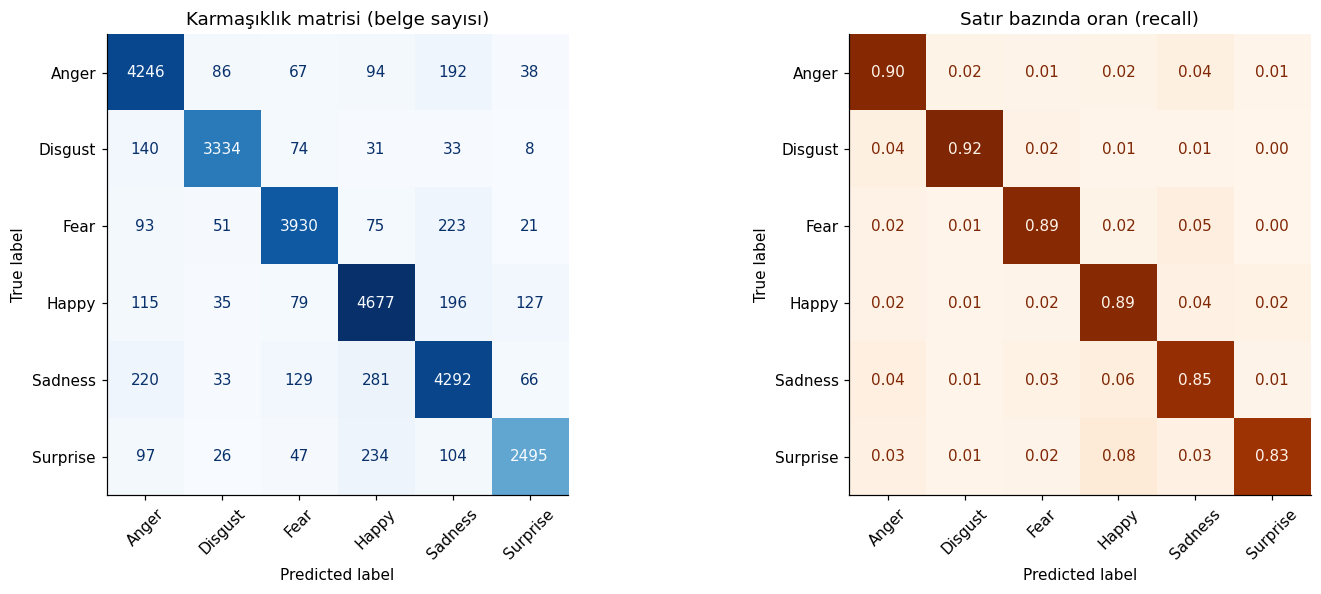

### En çok karışan sınıf çiftleri

Gerçek,Tahmin,Belge sayısı,Gerçek sınıfın %
Sadness,Happy,281,5.6
Surprise,Happy,234,7.8
Fear,Sadness,223,5.1
Sadness,Anger,220,4.4
Happy,Sadness,196,3.7
Anger,Sadness,192,4.1
Disgust,Anger,140,3.9
Sadness,Fear,129,2.6


### Cümle uzunluğuna göre doğruluk

Kelime sayısı,Doğruluk,Belge sayısı
1-2,0.858,2133
3-4,0.881,7685
5-7,0.883,10379
8-12,0.898,4718
13+,0.898,1074


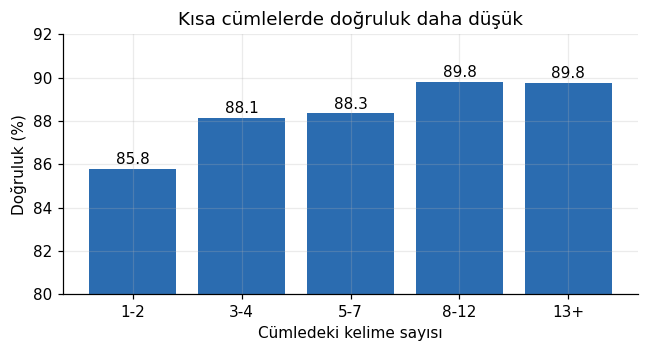

### Gerçek: Surprise | Tahmin: Happy  (234 belge, 8 örnek)

,text
0,Yengem kilosu olduğundan hamile olduğunu anlamamıştı. Sürpriz bir doğum oldu.
1,İlk defa deniz anası gördüğüm zaman.
2,Olağan dışı gelişmeler.
3,Sabri Sarıoğlu'nun yıllık aldığı parayı öğrenince.
4,Düşük beklediğim sınavdan yüksek not almak.
5,Başka bir okulu kazanmayı hayal ederken bu liseyi kazandığımı öğrendiğim an.
6,"""Göztepelilerin"" 100 metreyi 5 saniyede koşmasına."
7,Okulda ailemi görürsem.


### Gerçek: Sadness | Tahmin: Happy  (281 belge, 8 örnek)

,text
0,Beğendiğim botun numarası olmadığını öğrendiğimde.
1,Hiç yüzüm gülmedi ki.
2,100 yerine 99 almak.
3,Sağlık problemleri.
4,İstediğim bir şeyi başaramadığım zaman.
5,Test sorularını çözemediğim zaman.
6,Kuzenim şehit olduğu zaman.
7,Yaptığım proje istediğim gibi olmadığı zaman.


### Gerçek: Sadness | Tahmin: Anger  (220 belge, 8 örnek)

,text
0,Kendimi ifade edemediğimde ya da yanlış anlaşıldığımda.
1,en yakın arkadaşımla uzun süre konuşmadık çünkü ona saçlarının yağlı olduğunu söylediğim için bana küsmüştü
2,Öğretmenim çok uğraştığım projemi kabul etmedi.
3,Arkadaşımın dayak yemesi.
4,Dersleri anlamakta zorlandığım zaman.
5,Hayvanlara zarar verildiğinde.
6,Arkamdan konuşulması.
7,Arkadaşlarımın satması.


In [8]:
# ============================================================
# 8) HATA ANALİZİ (EN İYİ MODEL)
# ============================================================
EN_IYI = "Linear SVM (uni+bigram)"
tahmin = sonuc1[EN_IYI]["tahmin"]

# --- Sınıf bazında rapor ---
rap = pd.DataFrame(classification_report(y, tahmin, target_names=SINIFLAR, output_dict=True)).T
rap = rap.loc[SINIFLAR + ["macro avg", "weighted avg"], ["precision", "recall", "f1-score", "support"]]
baslik(f"Sınıf bazında sonuçlar: {EN_IYI}")
display(rap.style.format({"precision": "{:.3f}", "recall": "{:.3f}", "f1-score": "{:.3f}", "support": "{:.0f}"})
        .background_gradient(cmap="RdYlGn", subset=["precision", "recall", "f1-score"], vmin=0.8, vmax=0.95))
rap.reset_index().rename(columns={"index": "sinif"}).to_csv(f"{OUT_DIR}/tablo_sinif_raporu.csv", index=False)

# --- Karmaşıklık matrisi: sayılar ve satır bazında oran ---
fig, eksenler = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay.from_predictions(y, tahmin, display_labels=SINIFLAR, xticks_rotation=45,
                                        cmap="Blues", ax=eksenler[0], colorbar=False)
eksenler[0].set_title("Karmaşıklık matrisi (belge sayısı)")
ConfusionMatrixDisplay.from_predictions(y, tahmin, display_labels=SINIFLAR, xticks_rotation=45,
                                        cmap="Oranges", normalize="true", values_format=".2f",
                                        ax=eksenler[1], colorbar=False)
eksenler[1].set_title("Satır bazında oran (recall)")
for ax in eksenler: ax.grid(False)
plt.tight_layout(); kaydet_fig(fig, "grafik_karmasiklik_matrisi"); plt.show()

# --- En çok karışan sınıf çiftleri ---
cm = confusion_matrix(y, tahmin)
ciftler = [{"Gerçek": SINIFLAR[i], "Tahmin": SINIFLAR[j], "Belge sayısı": int(cm[i, j]),
            "Gerçek sınıfın %": 100 * cm[i, j] / cm[i].sum()}
           for i in range(len(SINIFLAR)) for j in range(len(SINIFLAR)) if i != j]
tab_cift = pd.DataFrame(ciftler).sort_values("Belge sayısı", ascending=False).head(8).reset_index(drop=True)
baslik("En çok karışan sınıf çiftleri")
display(tab_cift.style.hide(axis="index").format({"Gerçek sınıfın %": "{:.1f}"})
        .background_gradient(cmap="Reds", subset=["Belge sayısı"]))
kaydet_tablo(tab_cift, "tablo_karisan_ciftler")

# --- Cümle uzunluğuna göre doğruluk ---
d = data.copy()
d["tahmin"] = le.inverse_transform(tahmin)
d["dogru"] = d["tahmin"] == d["validated"]
d["kelime"] = d["clean"].str.split().str.len()
aralik = pd.cut(d["kelime"], [0, 2, 4, 7, 12, 1000], labels=["1-2", "3-4", "5-7", "8-12", "13+"])
uz = d.groupby(aralik, observed=True)["dogru"].agg(["mean", "count"]).reset_index()
uz.columns = ["Kelime sayısı", "Doğruluk", "Belge sayısı"]
baslik("Cümle uzunluğuna göre doğruluk")
display(uz.style.hide(axis="index").format({"Doğruluk": "{:.3f}"})
        .background_gradient(cmap="Greens", subset=["Doğruluk"]))
kaydet_tablo(uz, "tablo_uzunluk")

fig, ax = plt.subplots(figsize=(6, 3.3))
ax.bar(uz["Kelime sayısı"].astype(str), 100 * uz["Doğruluk"], color=MAVI)
ax.set_ylim(80, 92); ax.set_xlabel("Cümledeki kelime sayısı"); ax.set_ylabel("Doğruluk (%)")
ax.set_title("Kısa cümlelerde doğruluk daha düşük")
for i, v in enumerate(100 * uz["Doğruluk"]): ax.text(i, v + 0.2, f"{v:.1f}", ha="center")
plt.tight_layout(); kaydet_fig(fig, "grafik_uzunluk"); plt.show()

# --- Yanlış sınıflandırılan örnekler (rapora yorumlamak için) ---
pd.set_option("display.max_colwidth", 140)
for gercek, tah in [("Surprise", "Happy"), ("Sadness", "Happy"), ("Sadness", "Anger")]:
    alt = d[(d["validated"] == gercek) & (d["tahmin"] == tah)]
    baslik(f"Gerçek: {gercek} | Tahmin: {tah}  ({len(alt)} belge, 8 örnek)")
    display(alt[["text"]].sample(min(8, len(alt)), random_state=1).reset_index(drop=True))

## 9. Bulgular özeti ve çıktıları indirme

In [11]:
# ============================================================
# 9) BULGULAR ÖZETİ + ÇIKTILARI ZIP OLARAK İNDİR
# ============================================================
en_iyi_satir = tab1.iloc[0]
ozet_tablo = pd.DataFrame([
    ("En iyi model (Macro-F1)", f"{en_iyi_satir['Model']}: %{en_iyi_satir['Doğruluk (%)']:.2f} doğruluk, %{en_iyi_satir['Macro-F1 (%)']:.2f} F1"),
    ("Kök bulma kazancı (F5 - stemsiz)", f"{fark(sonuc2['F5 (makaledeki)'], sonuc2['Stemsiz'])[0]:+.2f} puan"),
    ("F5 - TurkishStemmer farkı", f"{fark(sonuc2['F5 (makaledeki)'], sonuc2['TurkishStemmer'])[0]:+.2f} puan"),
    ("Bigram etkisi", f"{fark(a2, a1)[0]:+.2f} ± {fark(a2, a1)[1]:.2f} puan"),
    ("MI seçiminin maliyeti", f"{fark(a3, a1)[0]:+.2f} ± {fark(a3, a1)[1]:.2f} puan"),
    ("Sızıntı etkisi (seçim bölmeden önce)", f"{fark(a4, a3)[0]:+.2f} ± {fark(a4, a3)[1]:.2f} puan"),
    ("Rastgele - gruplu bölme farkı", f"{100*(r_rast['acc'].mean()-r_grup['acc'].mean()):+.2f} puan"),
], columns=["Bulgu", "Değer"])
baslik("Bulgular özeti")
display(ozet_tablo.style.hide(axis="index").set_properties(**{"text-align": "left"})
        .set_table_styles([{"selector": "th", "props": [("background-color", "#2b6cb0"), ("color", "white")]}]))
kaydet_tablo(ozet_tablo, "tablo_bulgular_ozeti")

# --- Tüm tablo ve grafikleri zip yapıp indir (Colab'da) ---
import shutil
shutil.make_archive("ciktilar", "zip", OUT_DIR)
print("Hazır:", sorted(os.listdir(OUT_DIR)))
try:
    from google.colab import files
    files.download("ciktilar.zip")
except ImportError:
    print("Colab dışında çalışıyor; ciktilar.zip çalışma klasöründe.")

### Bulgular özeti

Bulgu,Değer
En iyi model (Macro-F1),"Linear SVM (uni+bigram): %88.40 doğruluk, %88.52 F1"
Kök bulma kazancı (F5 - stemsiz),+1.51 puan
F5 - TurkishStemmer farkı,+0.17 puan
Bigram etkisi,+0.77 ± 0.28 puan
MI seçiminin maliyeti,-0.41 ± 0.19 puan
Sızıntı etkisi (seçim bölmeden önce),+0.47 ± 0.09 puan
Rastgele - gruplu bölme farkı,+0.08 puan


Hazır: ['grafik_ablasyon.png', 'grafik_karmasiklik_matrisi.png', 'grafik_kok_bulma.png', 'grafik_model_karsilastirma.png', 'grafik_uzunluk.png', 'tablo_ablasyon.csv', 'tablo_ablasyon_farklar.csv', 'tablo_bolme_yontemi.csv', 'tablo_bulgular_ozeti.csv', 'tablo_karisan_ciftler.csv', 'tablo_kok_bulma.csv', 'tablo_mcnemar.csv', 'tablo_model_karsilastirma.csv', 'tablo_sinif_raporu.csv', 'tablo_uzunluk.csv', 'tablo_veri_dogrulama.csv', 'tablo_veri_ozeti.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

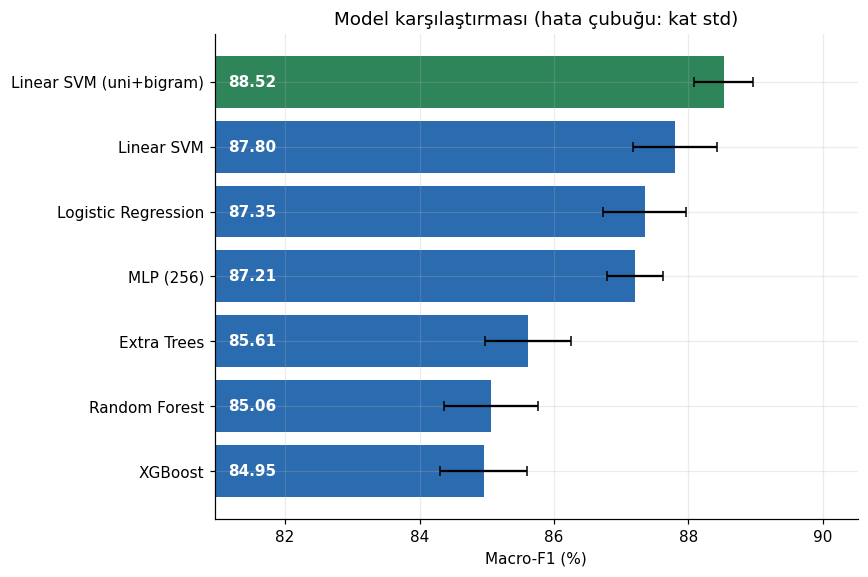

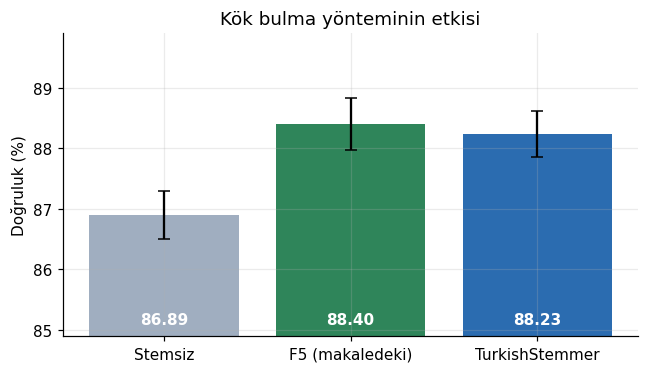

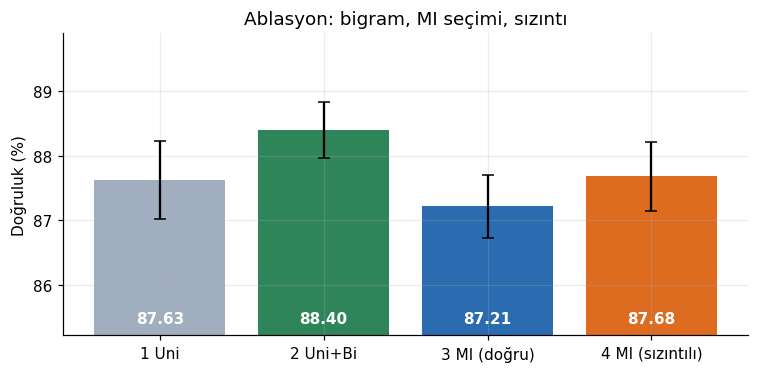

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

OUT_DIR = "ciktilar"
MAVI, YESIL, TURUNCU, GRI = "#2b6cb0", "#2f855a", "#dd6b20", "#a0aec0"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

def dikey_bar(df, etiket, deger, hata, renkler, baslik, dosya, boyut=(7, 3.5)):
    fig, ax = plt.subplots(figsize=boyut)
    ax.bar(df[etiket], df[deger], yerr=df[hata], color=renkler, capsize=4)
    alt = df[deger].min() - 2
    ax.set_ylim(alt, df[deger].max() + 1.5)
    for i, v in enumerate(df[deger]):   # etiket çubuğun dibinde, hata çubuğuyla çakışmaz
        ax.text(i, alt + 0.15, f"{v:.2f}", ha="center", va="bottom", color="white", fontweight="bold")
    ax.set_ylabel("Doğruluk (%)"); ax.set_title(baslik)
    plt.tight_layout(); fig.savefig(f"{OUT_DIR}/{dosya}.png", dpi=200, bbox_inches="tight"); plt.show()

# 1) Model karşılaştırması
t1 = pd.read_csv(f"{OUT_DIR}/tablo_model_karsilastirma.csv")
fig, ax = plt.subplots(figsize=(8, 0.55 * len(t1) + 1.5))
renk = [YESIL] + [MAVI] * (len(t1) - 1)
ax.barh(t1["Model"][::-1], t1["Macro-F1 (%)"][::-1], xerr=t1["± F1"][::-1], color=renk[::-1], capsize=3)
xmin = t1["Macro-F1 (%)"].min() - 4
ax.set_xlim(xmin, t1["Macro-F1 (%)"].max() + 2)
for i, v in enumerate(t1["Macro-F1 (%)"][::-1]):
    ax.text(xmin + 0.2, i, f"{v:.2f}", va="center", color="white", fontweight="bold")
ax.set_xlabel("Macro-F1 (%)"); ax.set_title("Model karşılaştırması (hata çubuğu: kat std)")
plt.tight_layout(); fig.savefig(f"{OUT_DIR}/grafik_model_karsilastirma.png", dpi=200, bbox_inches="tight"); plt.show()

# 2) Kök bulma
t2 = pd.read_csv(f"{OUT_DIR}/tablo_kok_bulma.csv")
dikey_bar(t2, "Yöntem", "Doğruluk (%)", "± acc", [GRI, YESIL, MAVI],
          "Kök bulma yönteminin etkisi", "grafik_kok_bulma", (6, 3.5))

# 3) Ablasyon
t3 = pd.read_csv(f"{OUT_DIR}/tablo_ablasyon.csv")
t3["Kurulum"] = ["1 Uni", "2 Uni+Bi", "3 MI (doğru)", "4 MI (sızıntılı)"]
dikey_bar(t3, "Kurulum", "Doğruluk (%)", "± acc", [GRI, YESIL, MAVI, TURUNCU],
          "Ablasyon: bigram, MI seçimi, sızıntı", "grafik_ablasyon")